This notebook is used to plot the CSI and ATI timing intervals and analyze the class distribution

In [1]:
import blosc2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Define the path to your data folder (adjust if necessary)
data_dir = Path("../data/labeled")

The following code plots the head distribution in the labeled data

Total samples in dataset: 48


,identifier,layout,room,acquisition,headcount
0,a_a1_hash813694_1,a,a1,hash813694,1
1,a_a1_hash058655_2,a,a1,hash058655,2
2,a_a1_hash240174_2,a,a1,hash240174,2
3,a_a1_hash861722_3,a,a1,hash861722,3
4,a_a1_hash033659_3,a,a1,hash033659,3


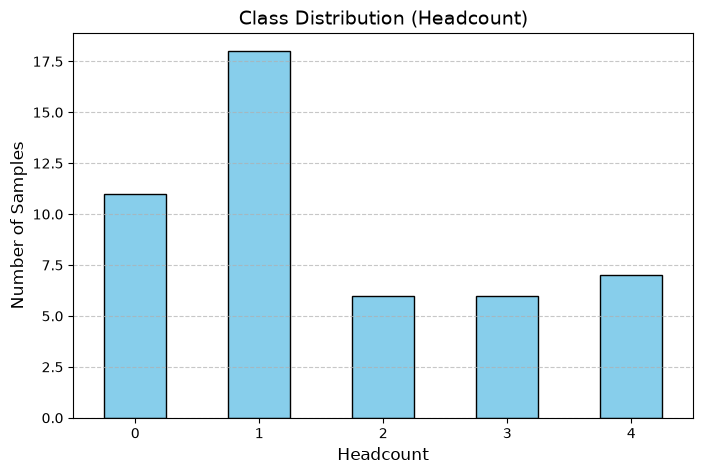

In [2]:
# Load the CSV file
csv_path = data_dir / "samples.csv"
df = pd.read_csv(csv_path)

# Display basic information
print(f"Total samples in dataset: {len(df)}")
display(df.head())

# Plot the class distribution
plt.figure(figsize=(8, 5))
# Count occurrences of each headcount (0 to 4, plus any 'unlabeled' traces)
class_counts = df['headcount'].astype(str).value_counts().sort_index()

class_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Class Distribution (Headcount)", fontsize=14)
plt.xlabel("Headcount", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Understanding the shape of a sample

In [3]:
# Pick the first valid identifier from the dataframe
sample_id = df['identifier'].iloc[47]
label = df['headcount'].iloc[47]

# Load CSI and ATI data
csi = blosc2.load_array(str(data_dir / f"CSI_{sample_id}.b2"))
ati = blosc2.load_array(str(data_dir / f"ATI_{sample_id}.b2"))

print(f"Loaded Sample ID: {sample_id} (Label: {label} people)")
print(f"CSI Shape: {csi.shape}, Type: {csi.dtype}")
print(f"ATI Shape: {ati.shape}, Type: {ati.dtype}")

Loaded Sample ID: g_g1_hash224345_1 (Label: 1 people)
CSI Shape: (12000, 1, 3, 1024), Type: complex64
ATI Shape: (12000,), Type: float32


<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:33: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_40472/3464149709.py:29: SyntaxWarning: invalid escape sequence '\m'
  ax2.set_ylabel("Interval ($\mu$s)", fontsize=12)
/tmp/ipykernel_40472/3464149709.py:33: SyntaxWarning: invalid escape sequence '\m'
  ax2.axhline(y=5000, color='r', linestyle=':', label='Expected (200 Hz = 5000 $\mu$s)')


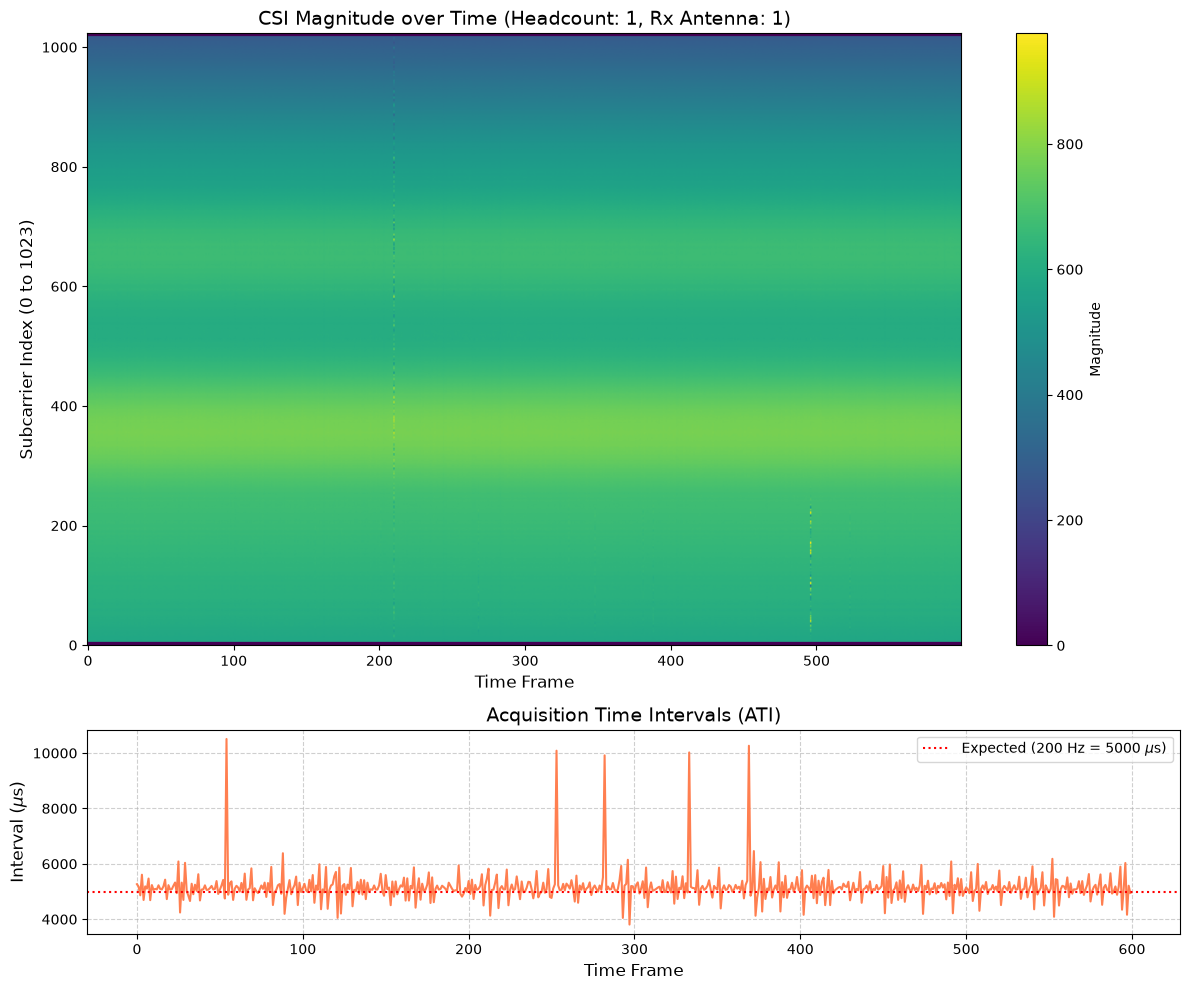

In [4]:
# 1. Prepare the CSI data
# Extract the first 600 frames to match the competition submission window
# Select Tx antenna 0 and Rx antenna 0
csi_window = csi[:600, 0, 0, :] 

# Calculate the magnitude of the complex values: np.abs(a + bi)
csi_magnitude = np.abs(csi_window)

# Transpose so that Time is on the X-axis and Subcarriers are on the Y-axis
csi_to_plot = csi_magnitude.T 

# 2. Prepare the ATI data
ati_window = ati[:600]

# 3. Create the plots
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10), gridspec_kw={'height_ratios': [3, 1]})

# Plot CSI Matrix
cax = ax1.imshow(csi_to_plot, aspect='auto', origin='lower', cmap='viridis')
ax1.set_title(f"CSI Magnitude over Time (Headcount: {label}, Rx Antenna: 1)", fontsize=14)
ax1.set_xlabel("Time Frame", fontsize=12)
ax1.set_ylabel("Subcarrier Index (0 to 1023)", fontsize=12)
fig.colorbar(cax, ax=ax1, label="Magnitude")

# Plot ATI Timings
ax2.plot(ati_window, color='coral', linewidth=1.5)
ax2.set_title("Acquisition Time Intervals (ATI)", fontsize=14)
ax2.set_xlabel("Time Frame", fontsize=12)
ax2.set_ylabel("Interval ($\mu$s)", fontsize=12)
ax2.grid(True, linestyle='--', alpha=0.6)

# Highlight the expected 200 Hz baseline (~5000 microseconds)
ax2.axhline(y=5000, color='r', linestyle=':', label='Expected (200 Hz = 5000 $\mu$s)')
ax2.legend()

plt.tight_layout()
plt.show()

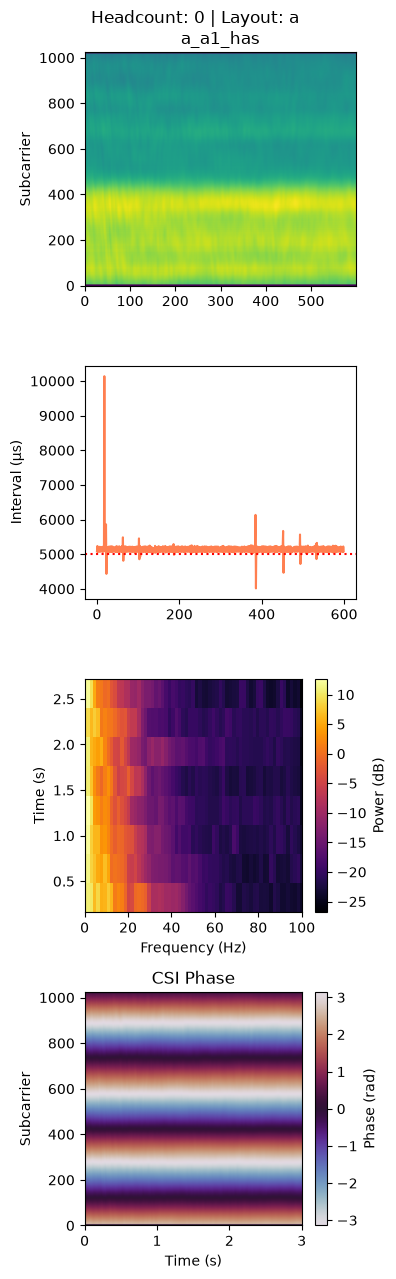

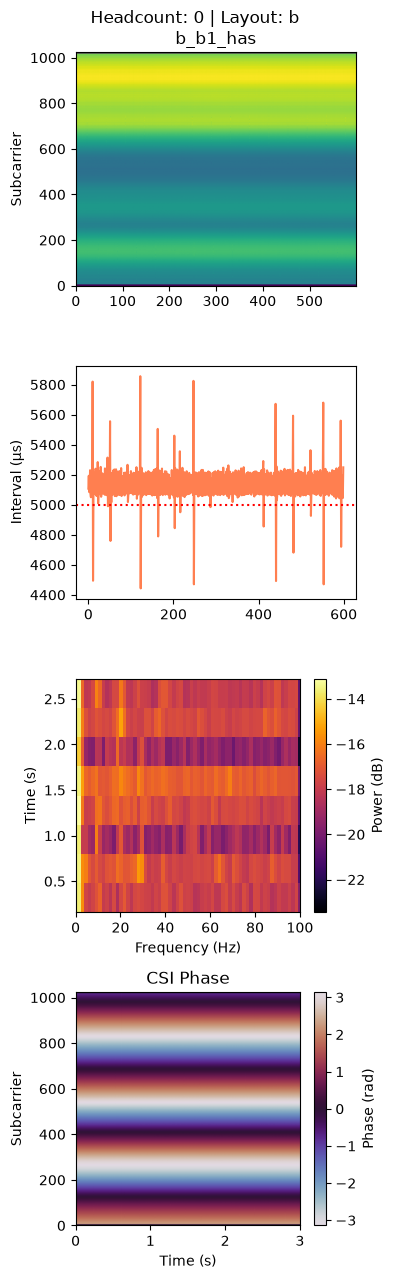

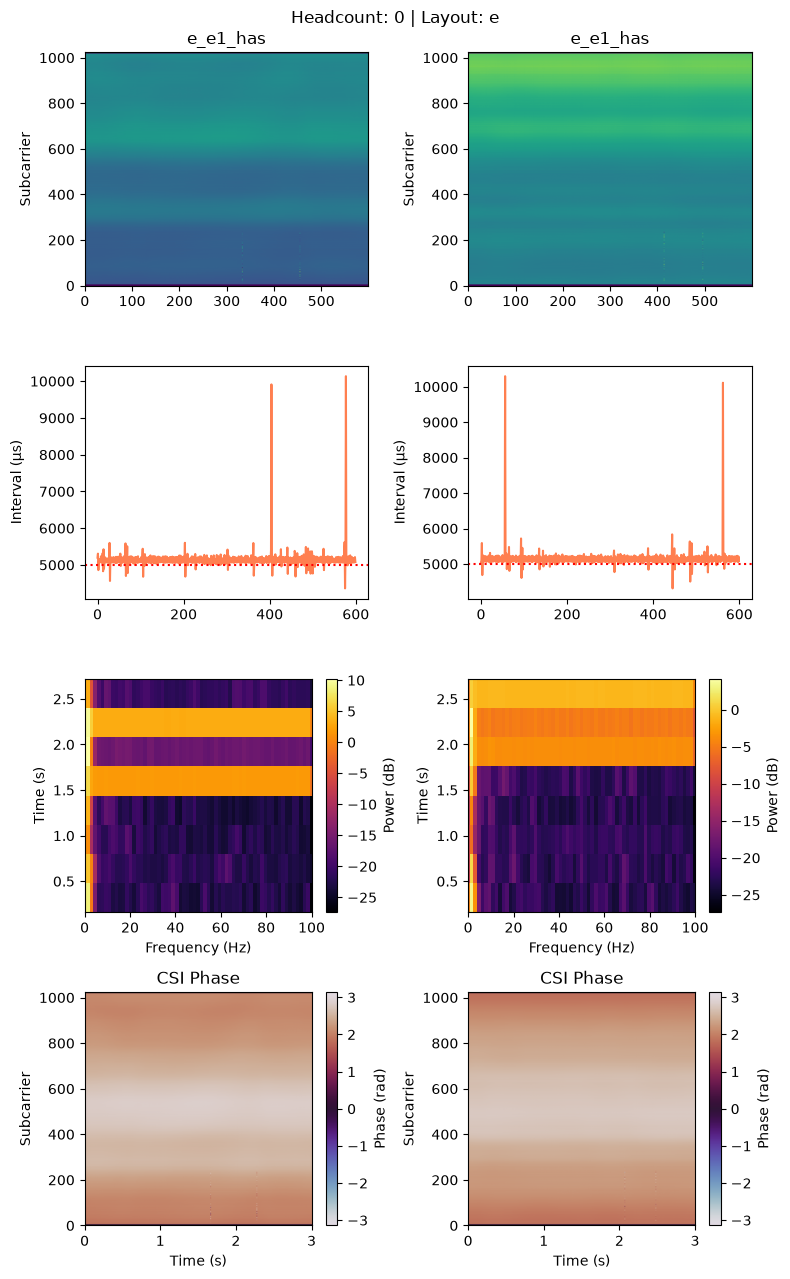

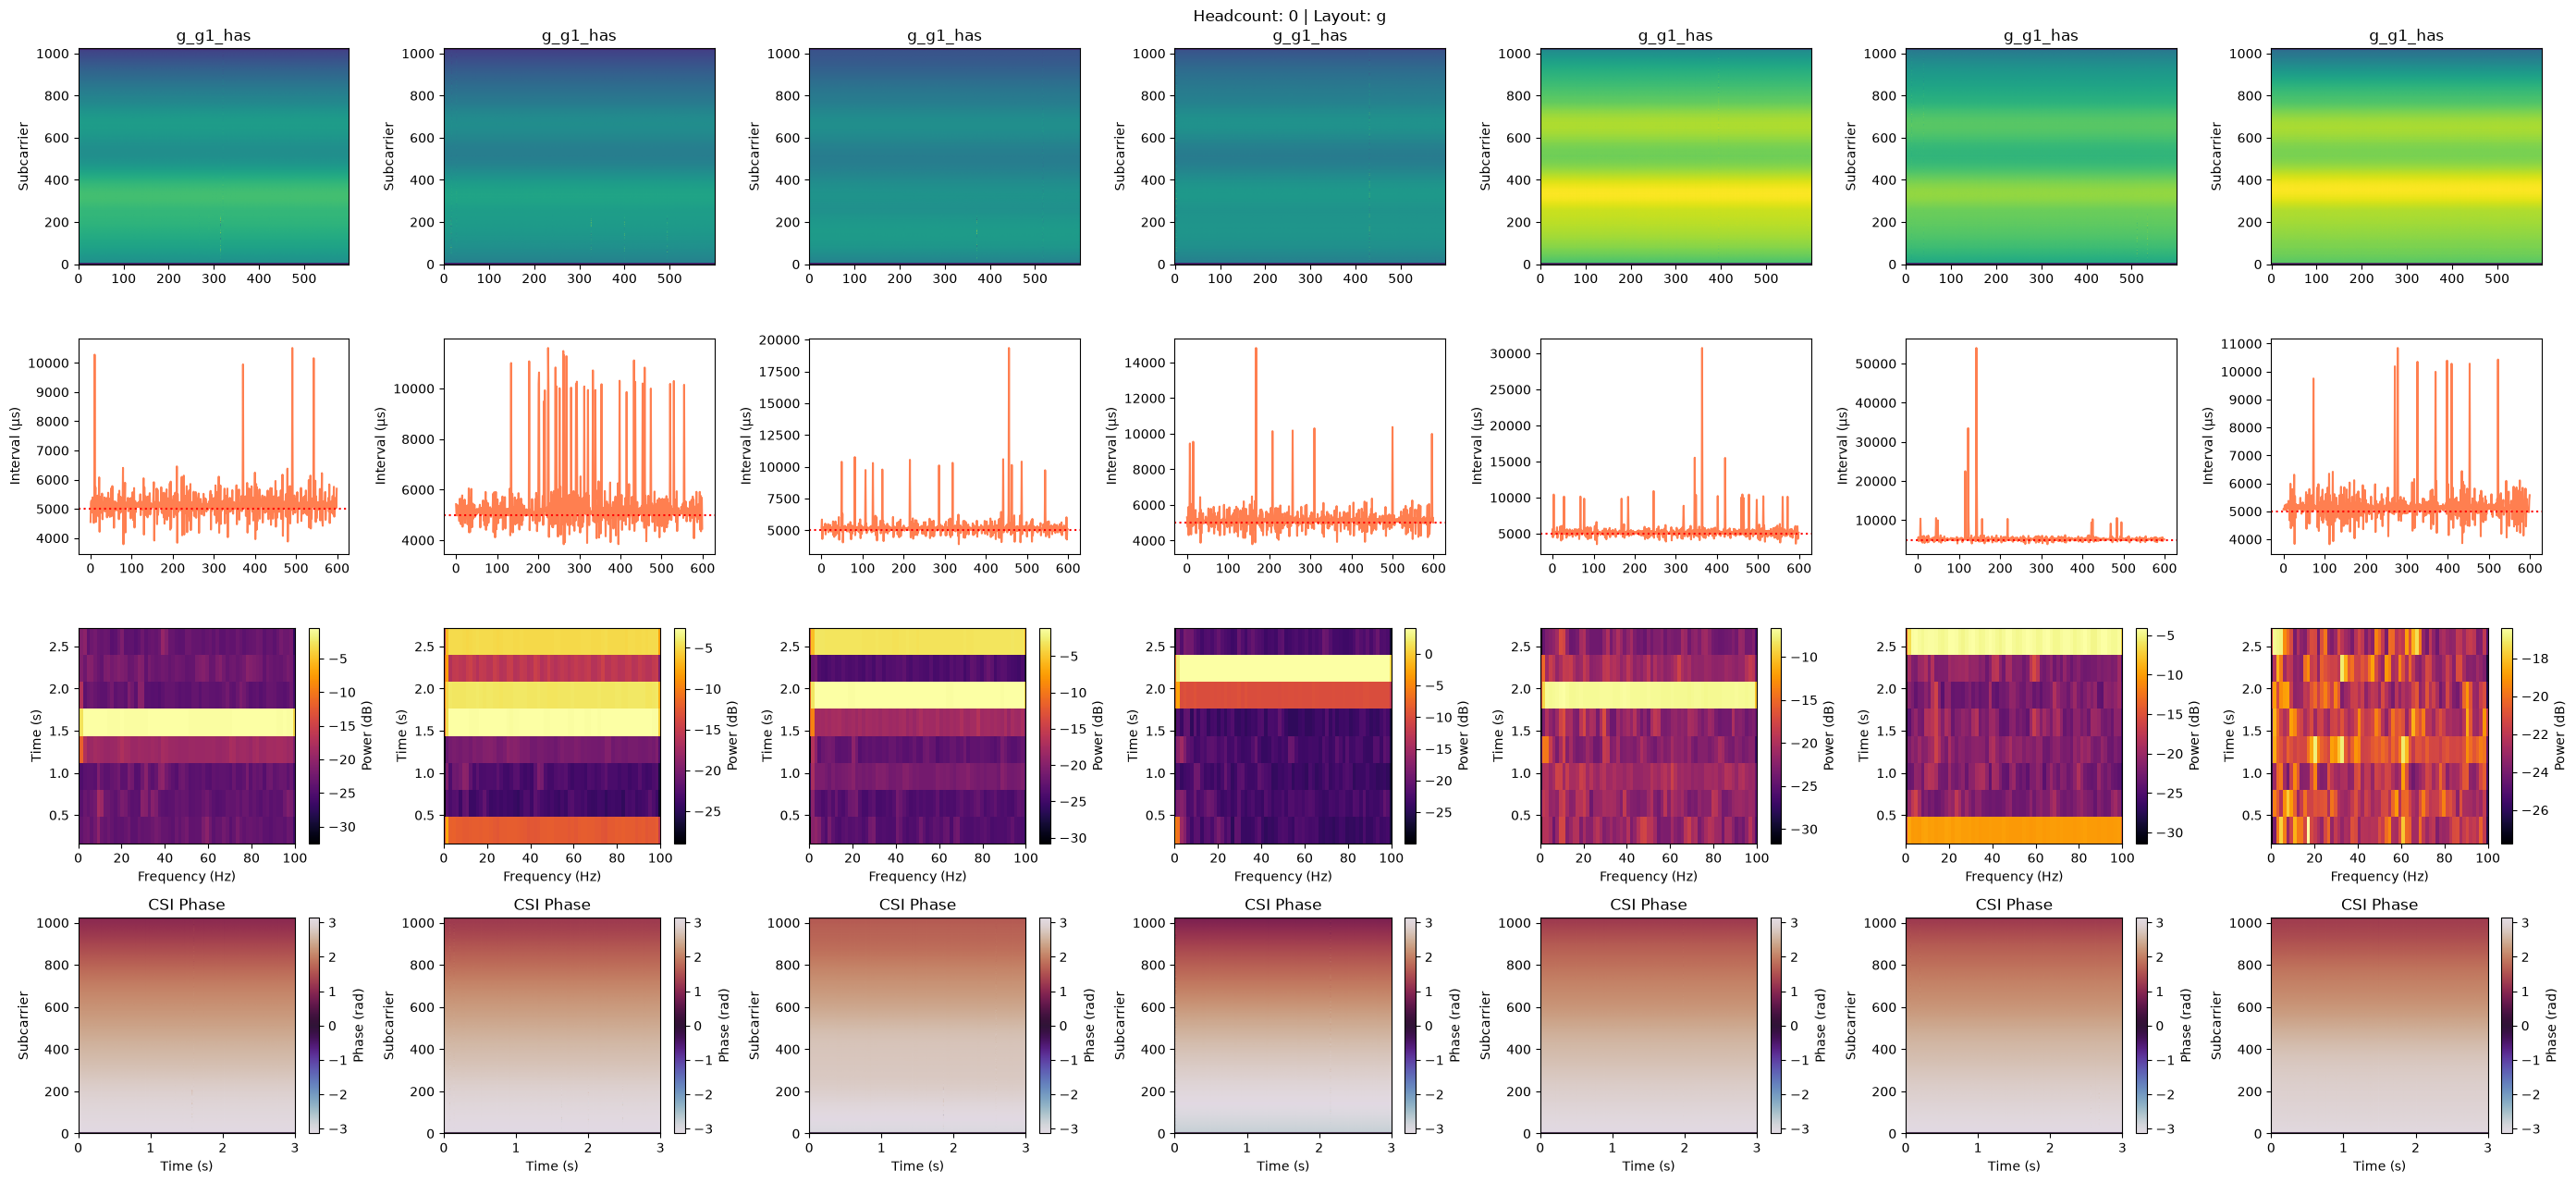

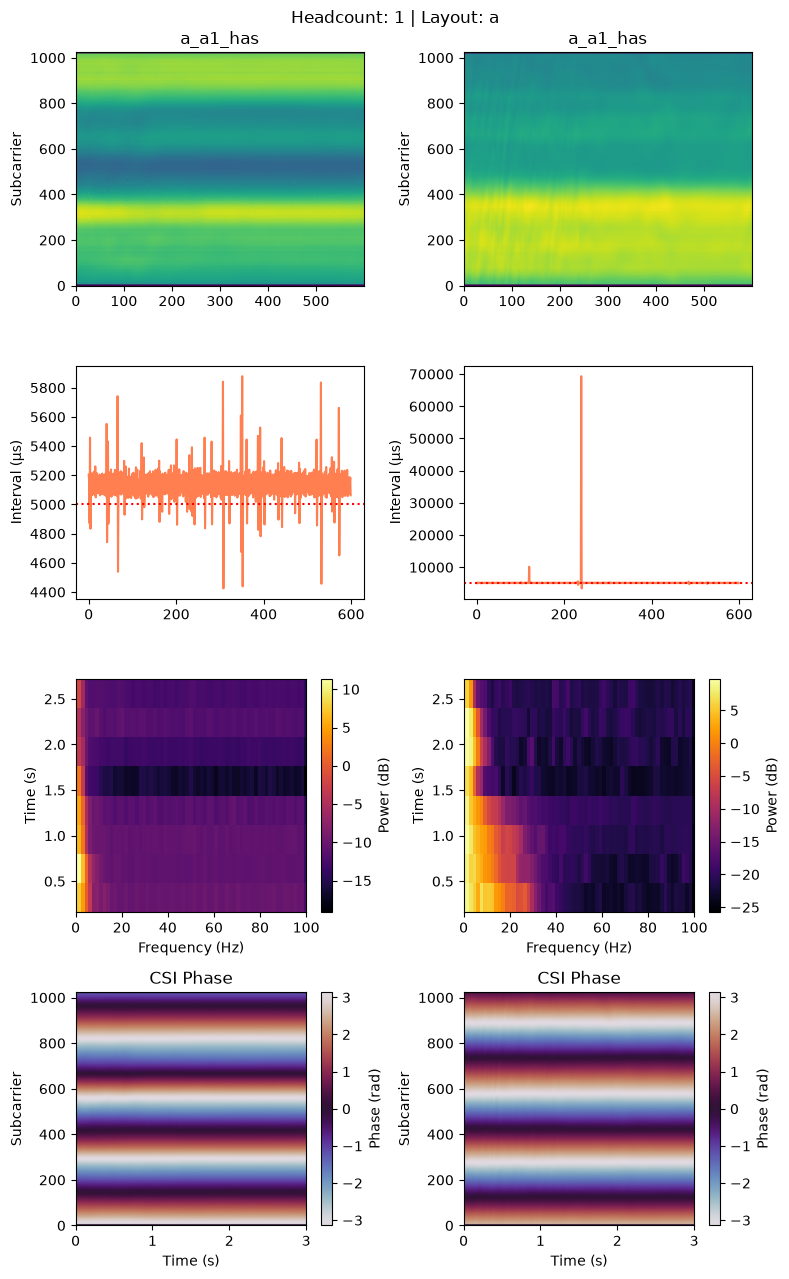

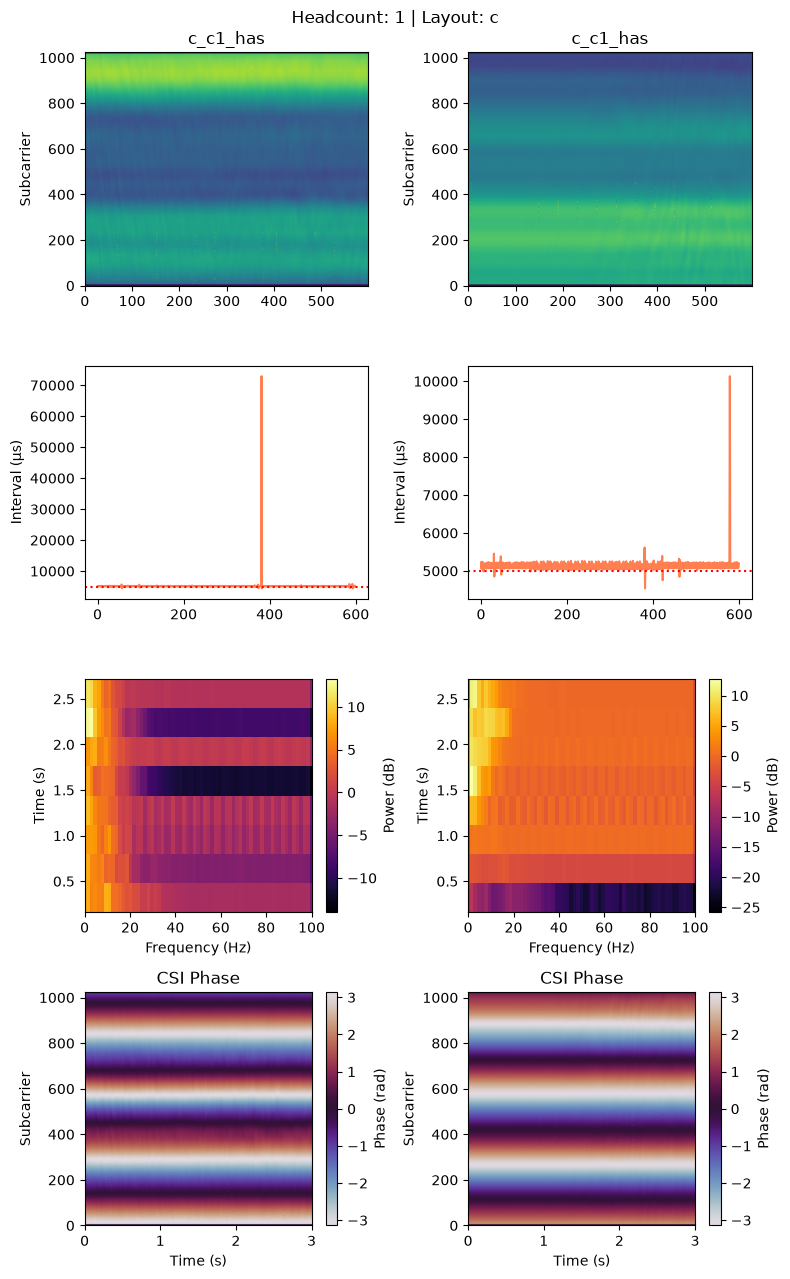

Missing sample: e_e1_hash250867_1


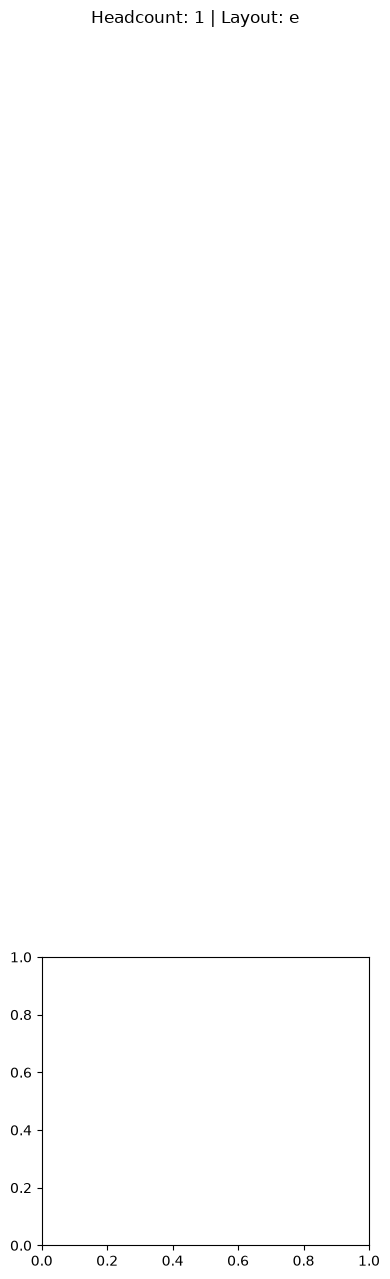

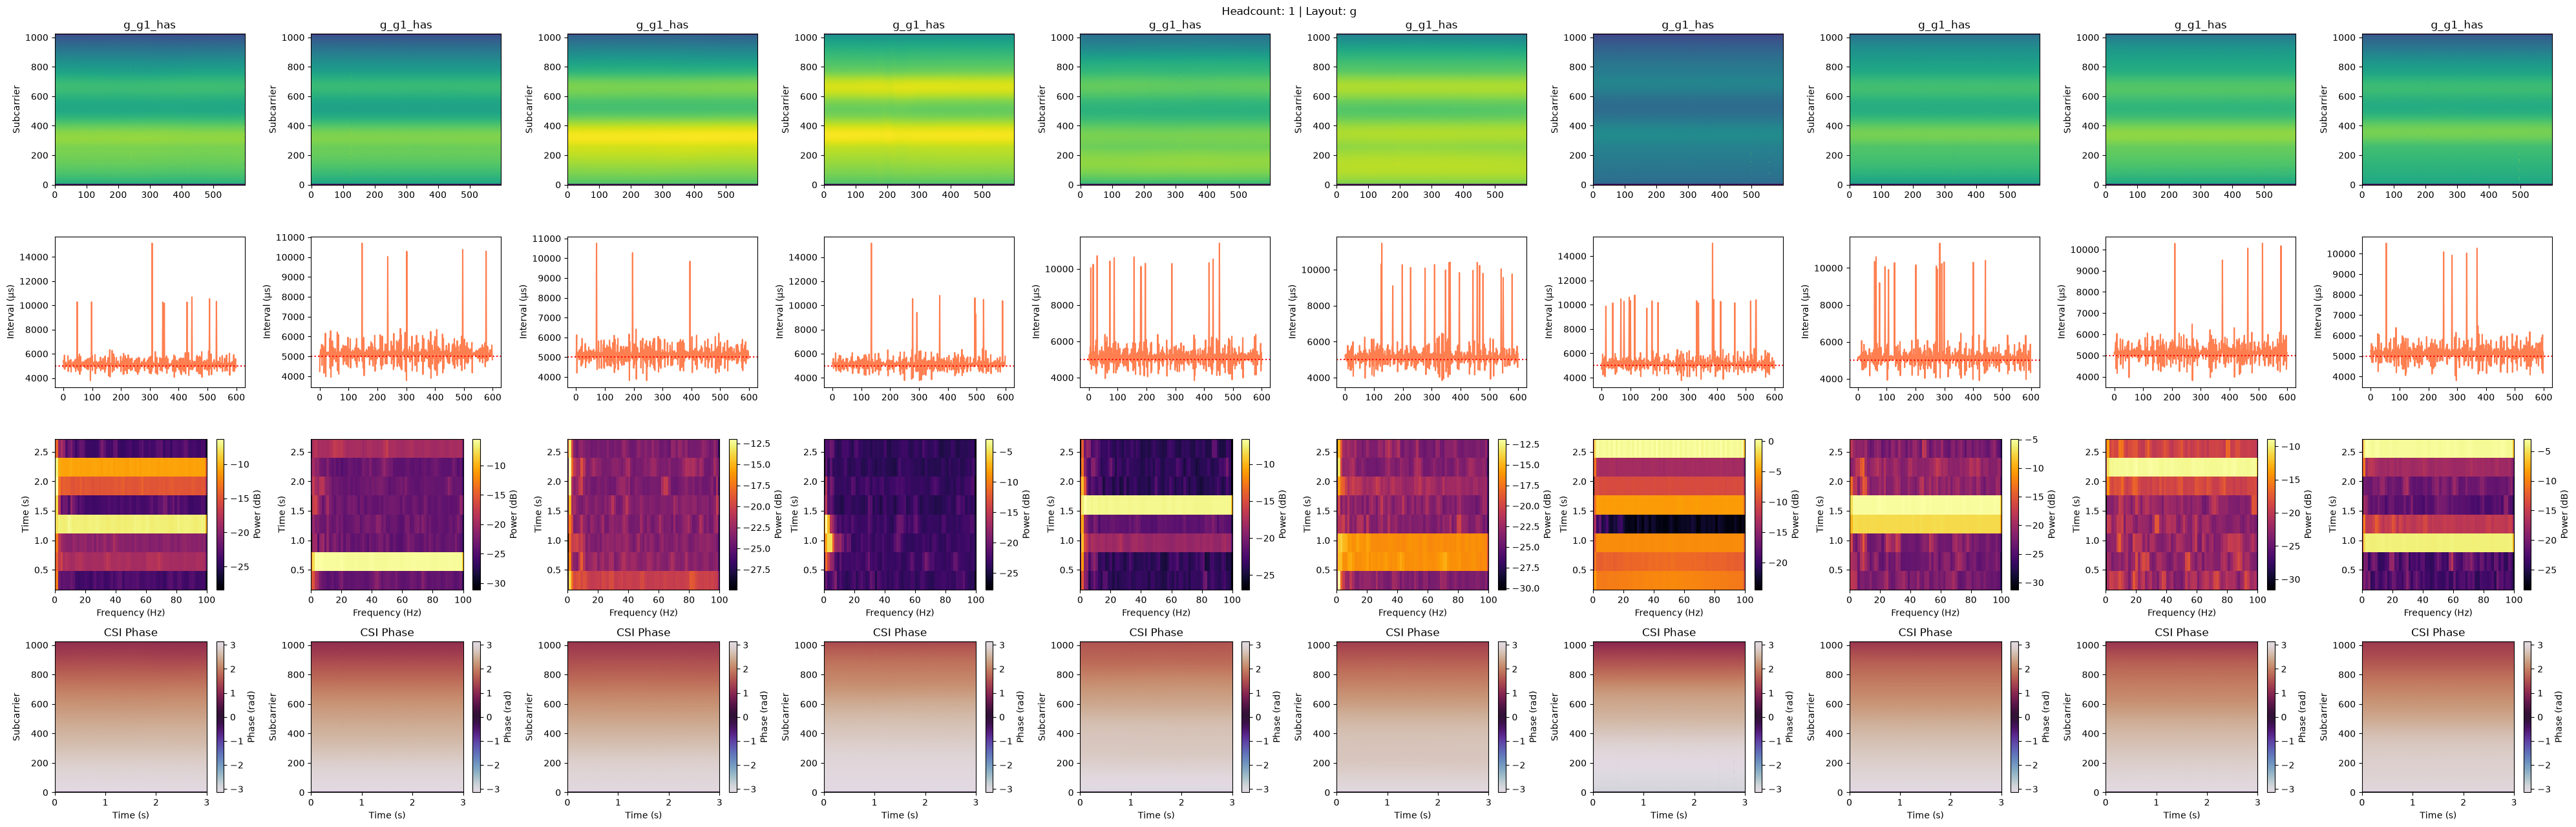

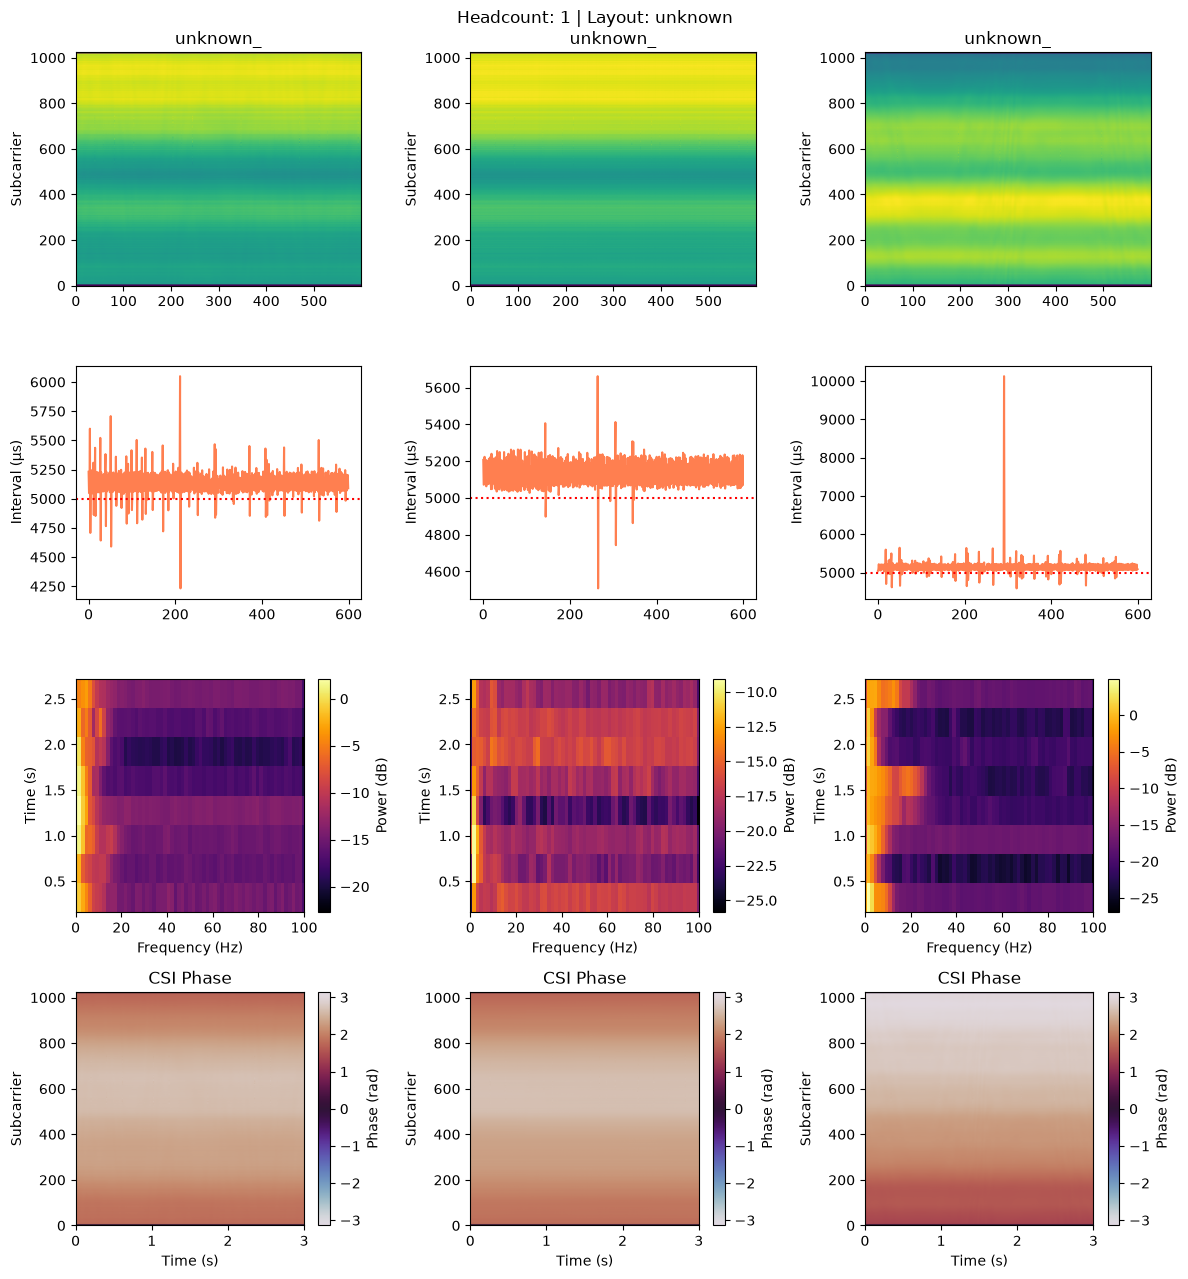

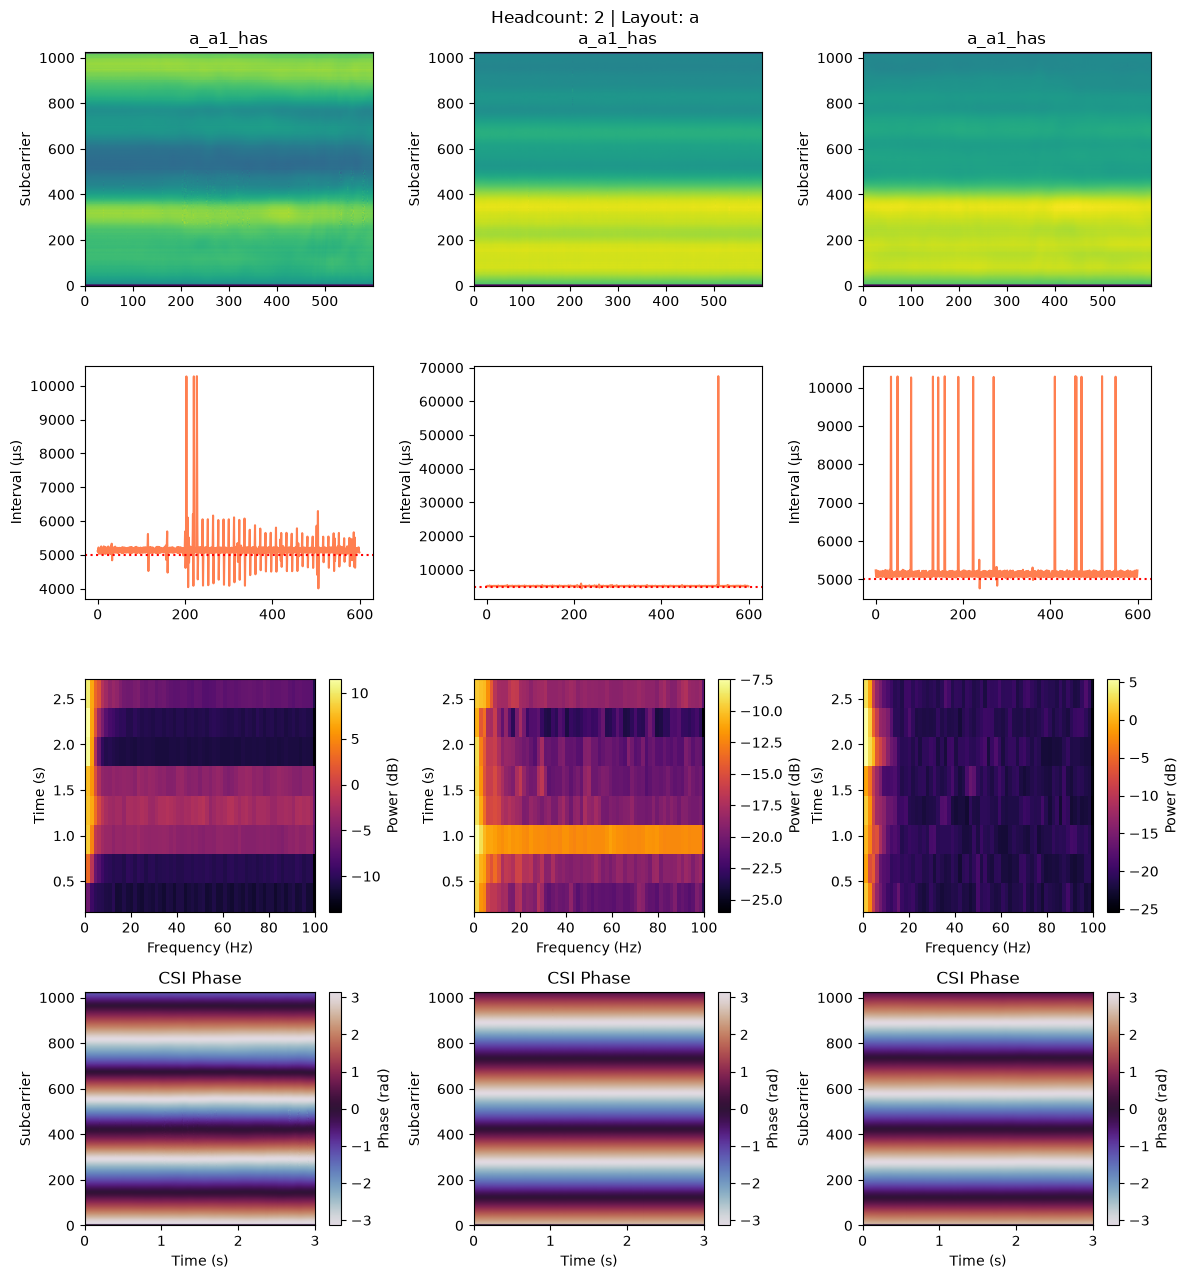

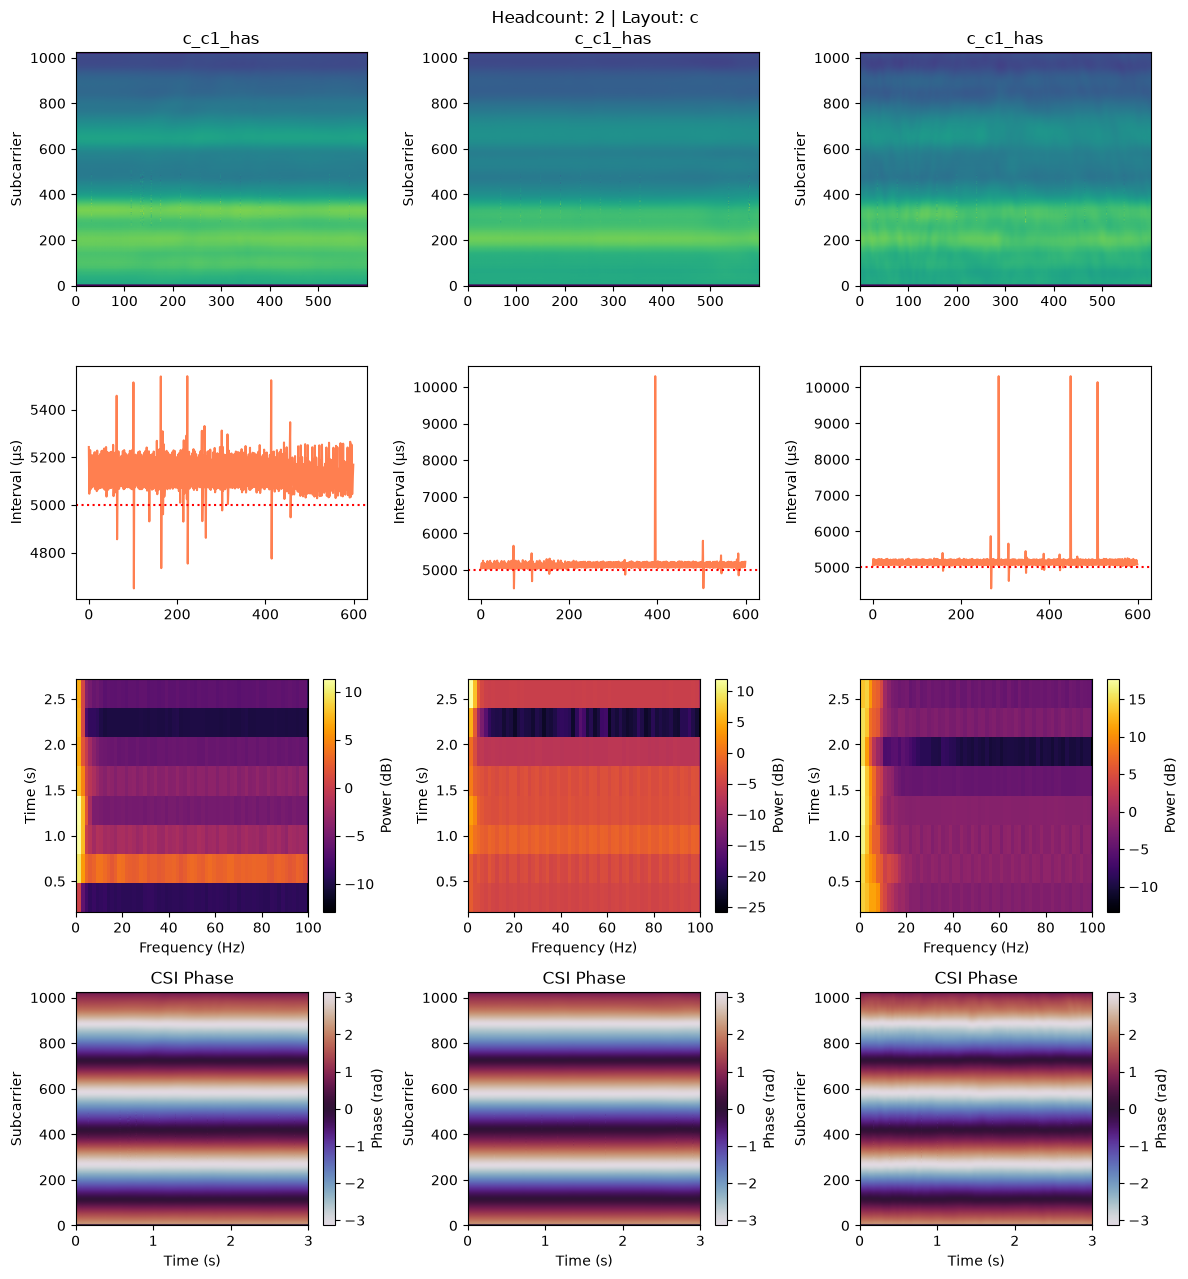

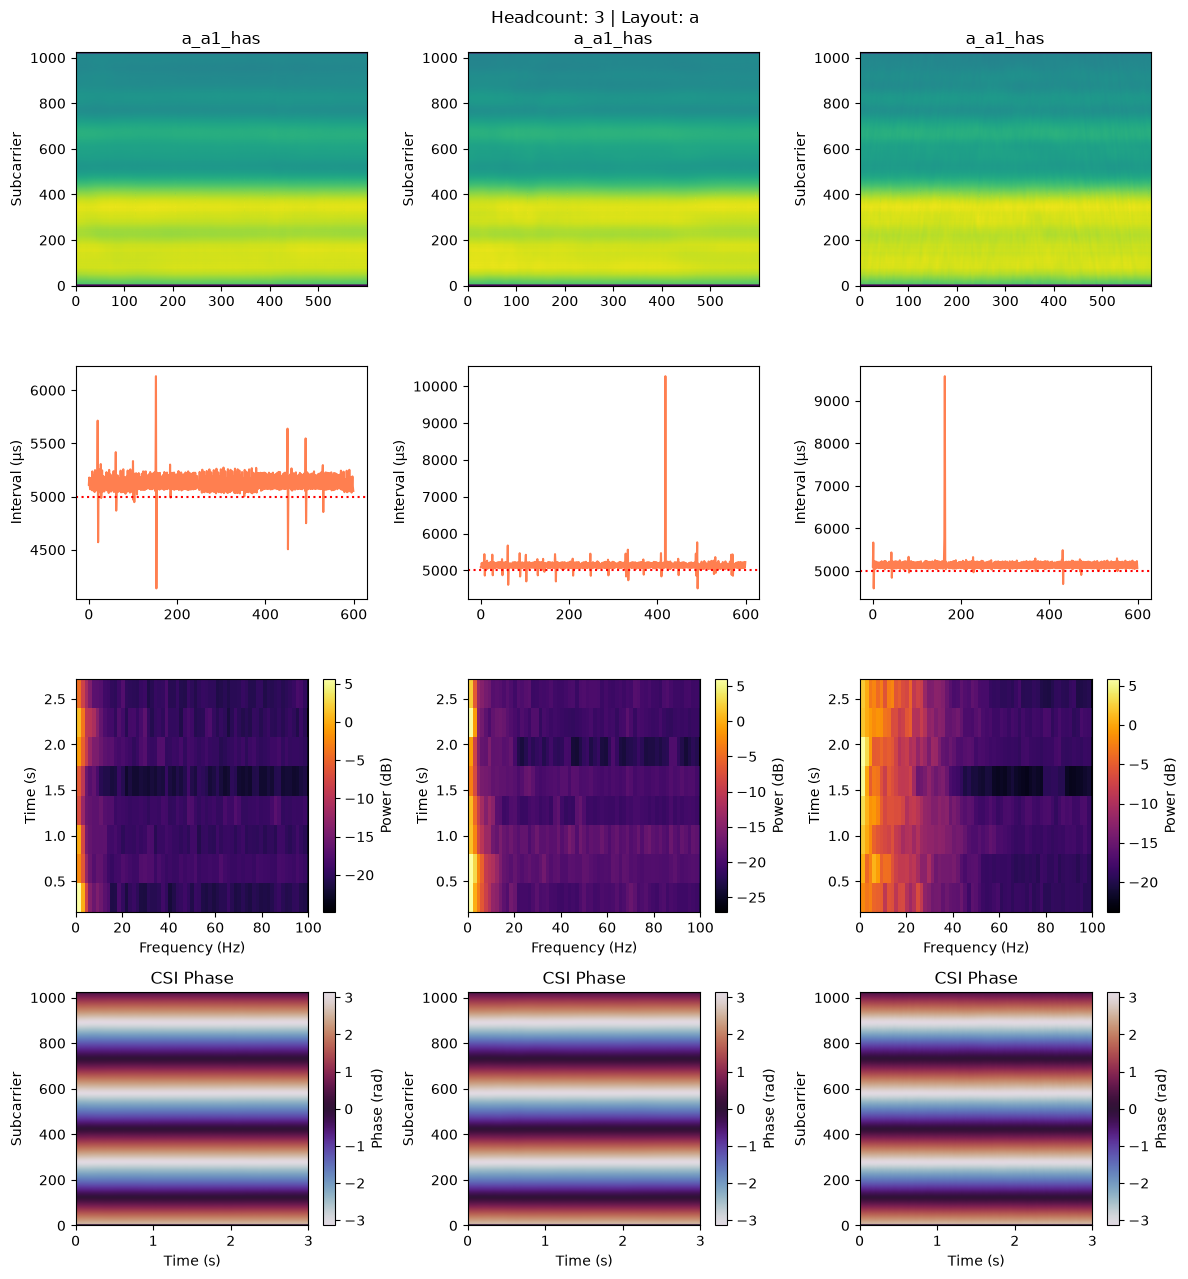

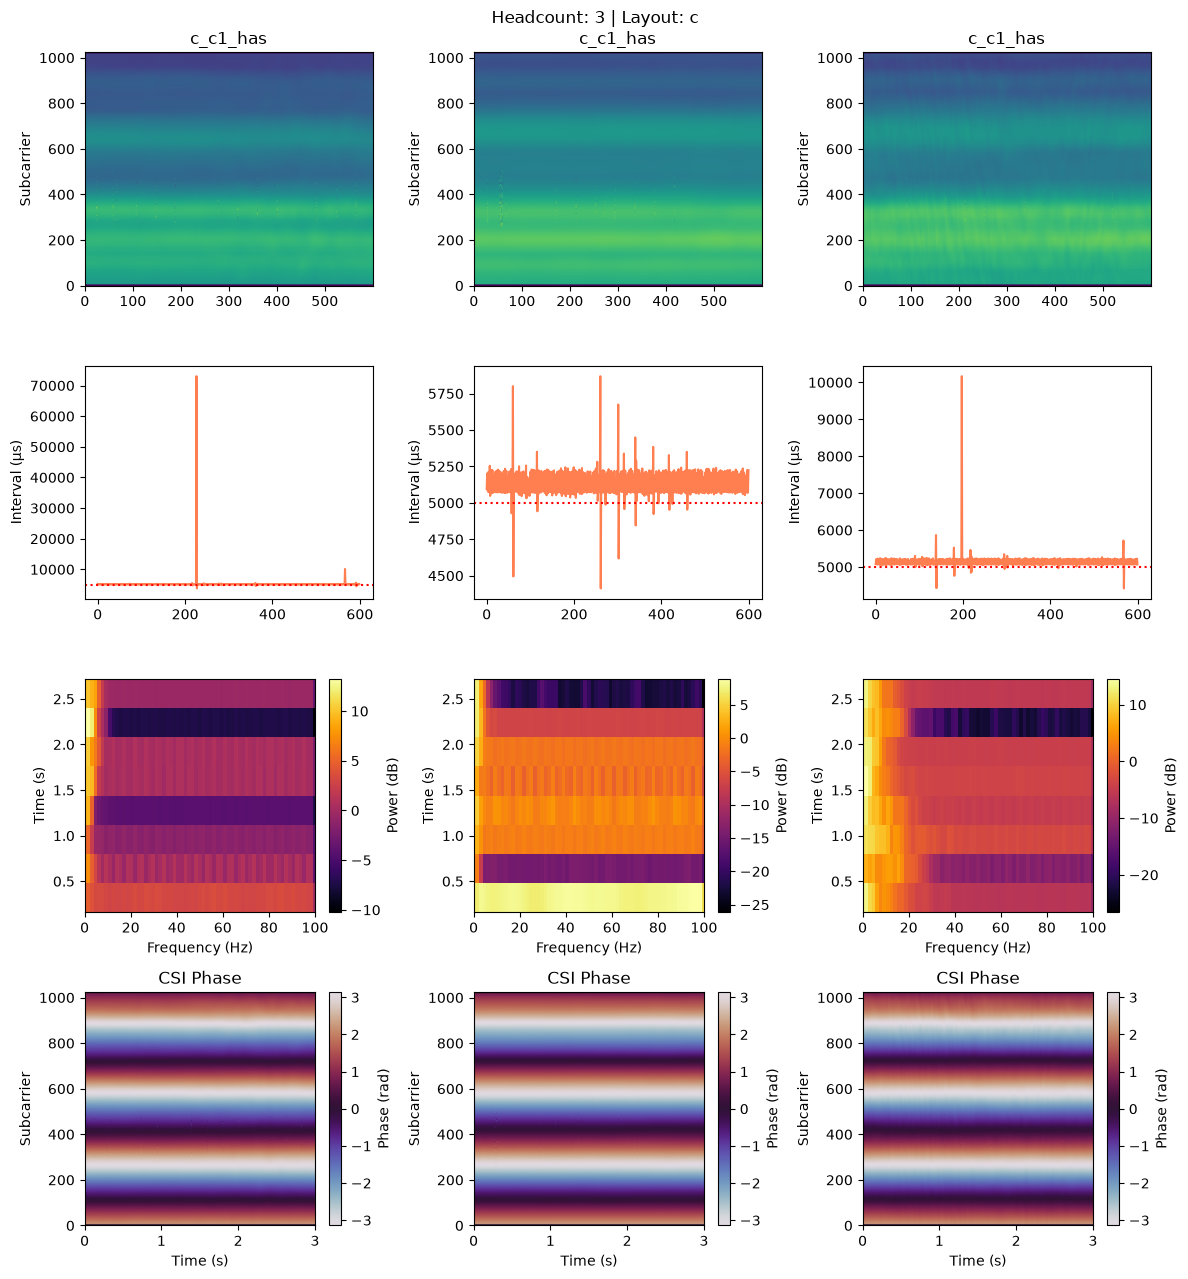

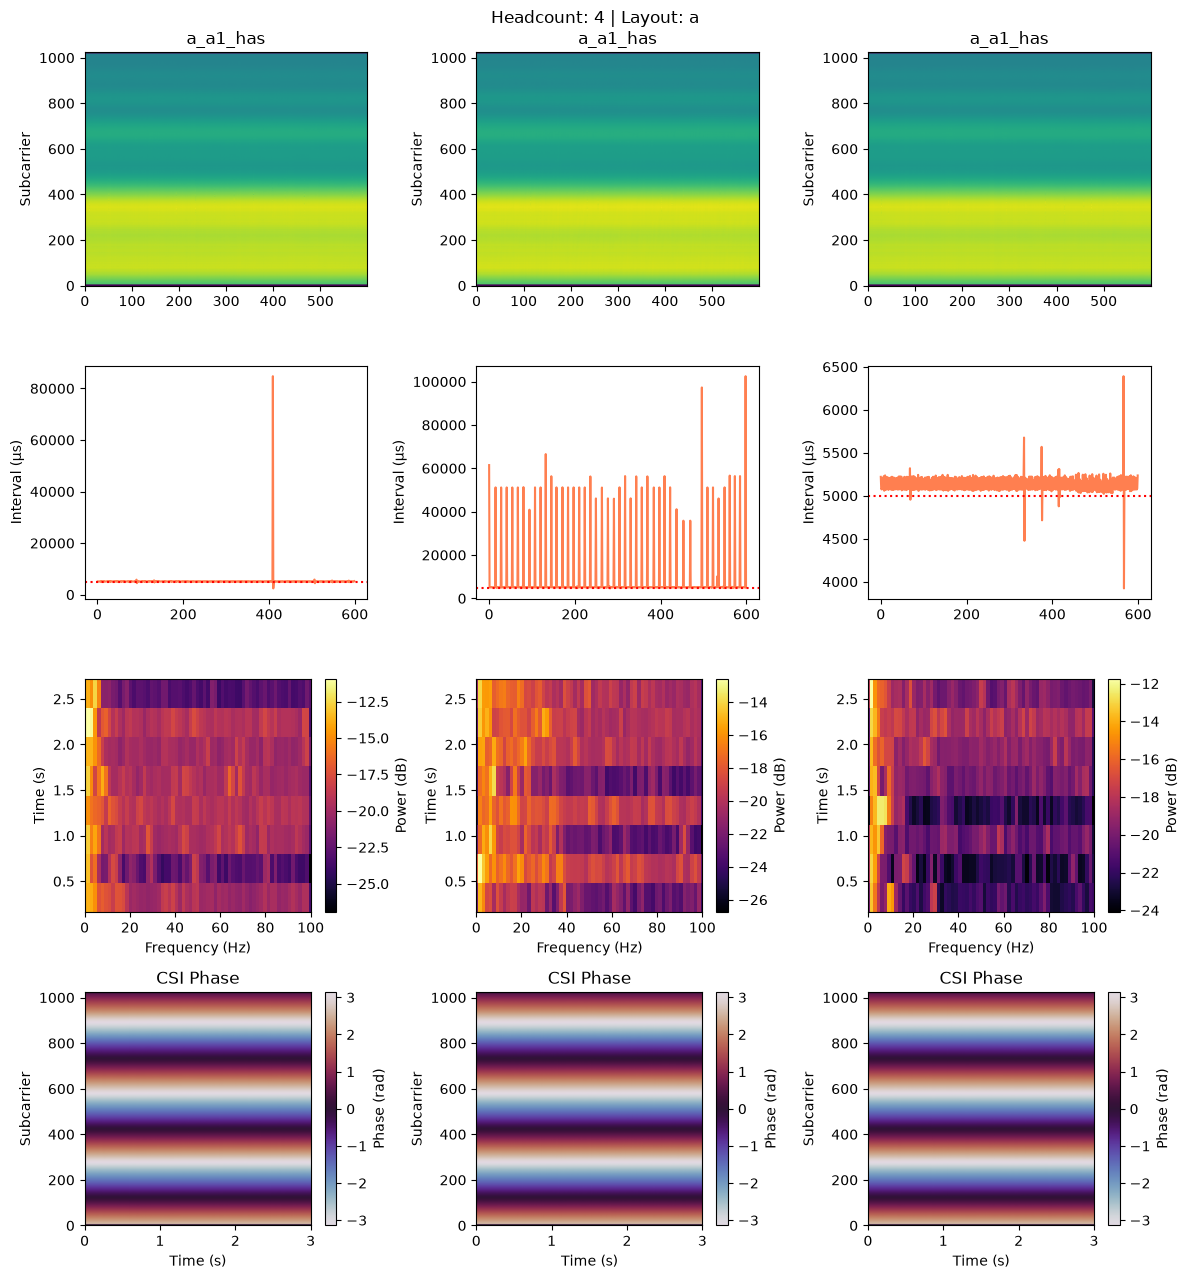

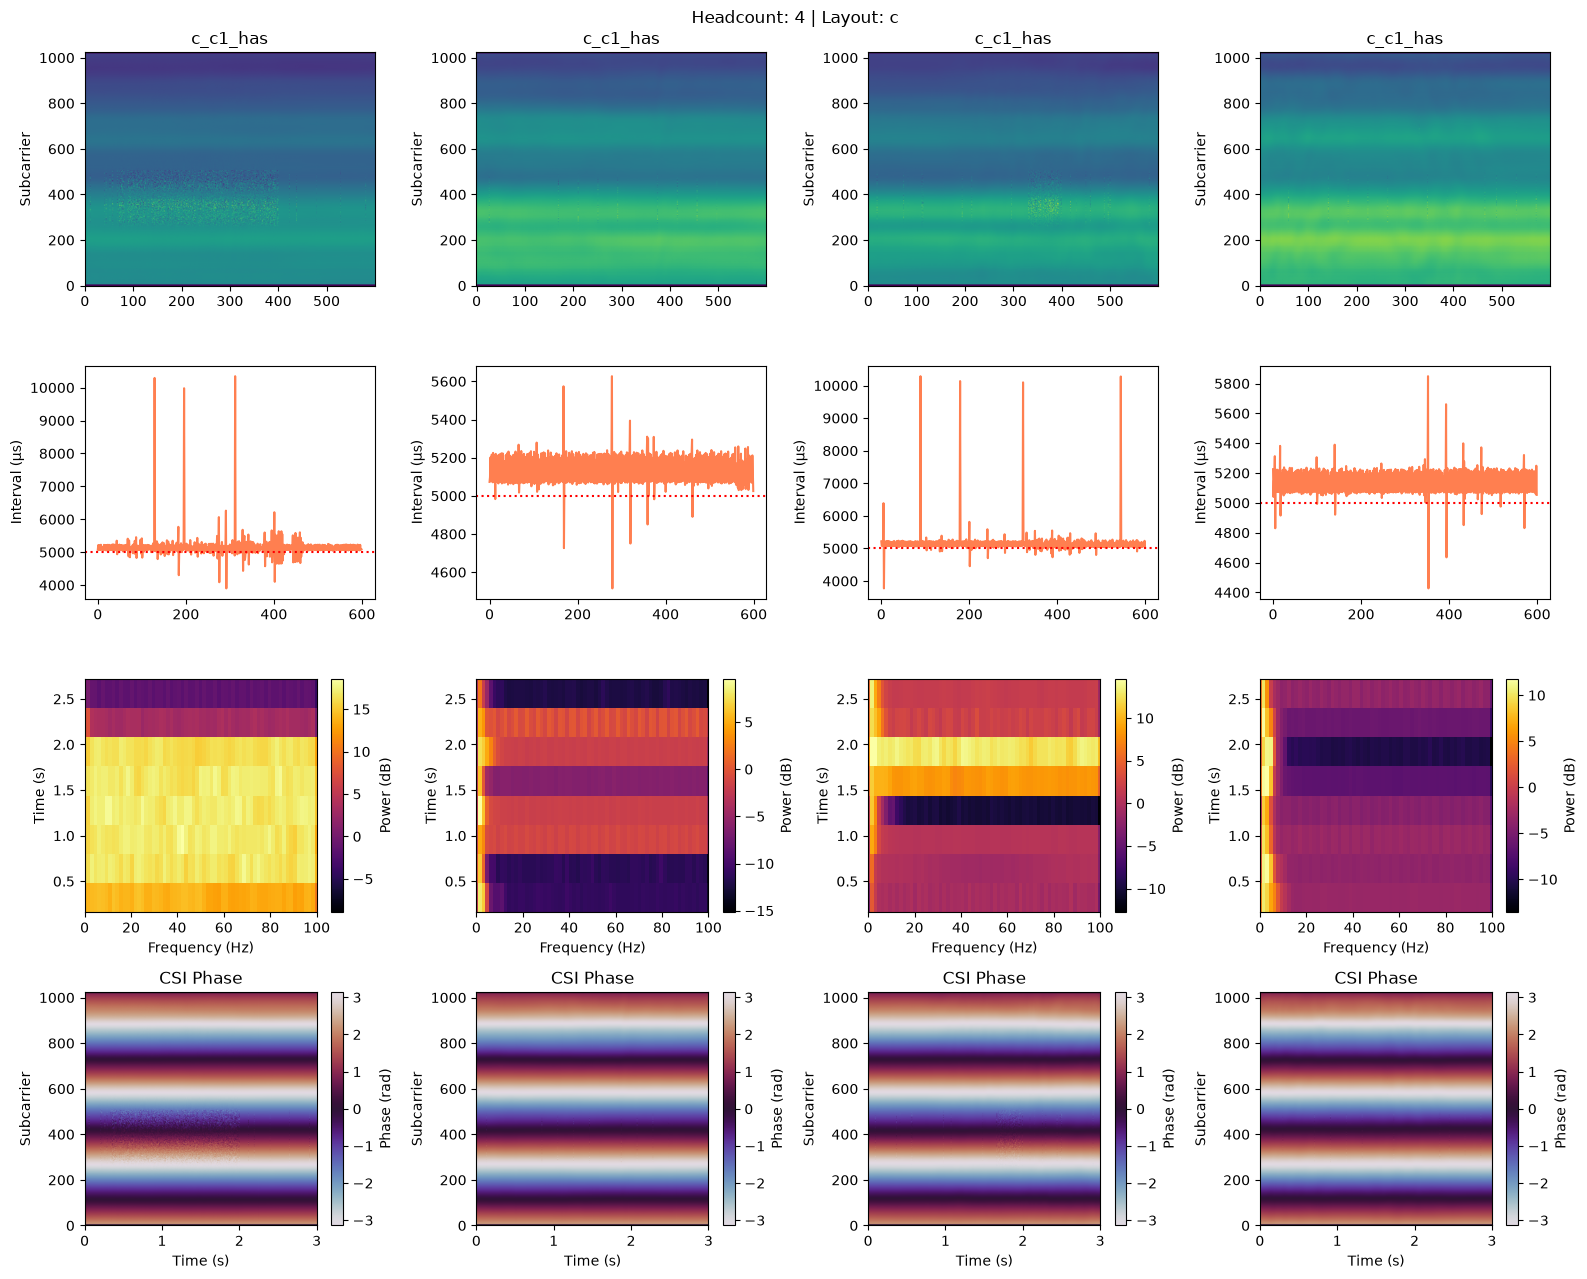

In [9]:

from scipy.signal import periodogram

fs = 200          # Sampling frequency (Hz)
window_size = 128 # Frames per periodogram
overlap = 64      # Overlapping frames

grouped_df = df.groupby(['headcount', 'layout'])

for (headcount, layout), group in grouped_df:
    fig, axes = plt.subplots(
        4, len(group),
        figsize=(4 * len(group), 13),
        squeeze=False
    )

    fig.suptitle(f"Headcount: {headcount} | Layout: {layout}")

    valid_count = 0

    for _, row in group.iterrows():
        sample_id = row['identifier']

        csi_path = data_dir / f"CSI_{sample_id}.b2"
        ati_path = data_dir / f"ATI_{sample_id}.b2"

        # Skip missing files
        if not csi_path.exists() or not ati_path.exists():
            print(f"Missing sample: {sample_id}")
            continue

        csi = blosc2.load_array(str(csi_path))
        ati = blosc2.load_array(str(ati_path))

        csi_window = np.abs(csi[:600, 0, 0, :])
        ati_window = ati[:600]

        # Remove temporal mean
        dynamic = csi_window - csi_window.mean(axis=0)

        # Sliding-window periodograms
        frequencies = None
        power_windows = []
        time_windows = []

        for start in range(0, len(dynamic) - window_size + 1,
                           window_size - overlap):

            segment = dynamic[start:start + window_size]

            frequencies, power = periodogram(
                segment,
                fs=fs,
                axis=0,
                window='hann',
                detrend='constant',
                scaling='density'
            )

            # Average spectral power across subcarriers
            power_windows.append(power.mean(axis=1))
            time_windows.append((start + window_size / 2) / fs)

        power_matrix = np.array(power_windows)

        # Convert to logarithmic scale
        power_db = 10 * np.log10(power_matrix + 1e-12)

        # Plot in next available column
        i = valid_count
        valid_count += 1

        # CSI
        axes[0, i].imshow(
            csi_window.T,
            aspect='auto',
            origin='lower',
            cmap='viridis'
        )
        axes[0, i].set_title(sample_id[:8])
        axes[0, i].set_ylabel("Subcarrier")

        # ATI
        axes[1, i].plot(ati_window, color='coral')
        axes[1, i].axhline(5000, color='red', linestyle=':')
        axes[1, i].set_ylabel("Interval (µs)")

        # Periodogram heatmap
        mesh = axes[2, i].pcolormesh(
            frequencies,
            time_windows,
            power_db,
            shading='auto',
            cmap='inferno'
        )

        axes[2, i].set_xlabel("Frequency (Hz)")
        axes[2, i].set_ylabel("Time (s)")
        axes[2, i].set_xlim(0, fs / 2)

        fig.colorbar(mesh, ax=axes[2, i], label="Power (dB)")

        # Extract phase
        phase_window = np.angle(csi[:600, 0, 0, :])

        # Plot phase heatmap
        im = axes[3, i].imshow(
            phase_window.T,
            aspect='auto',
            origin='lower',
            cmap='twilight',
            vmin=-np.pi,
            vmax=np.pi,
            extent=[0, len(phase_window) / fs,
                    0, phase_window.shape[1]]
        )

        axes[3, i].set_xlabel("Time (s)")
        axes[3, i].set_ylabel("Subcarrier")
        axes[3, i].set_title("CSI Phase")
        fig.colorbar(im, ax=axes[3, i], label="Phase (rad)")


    # Hide unused columns
    for i in range(valid_count, len(group)):
        for j in range(3):
            axes[j, i].set_visible(False)

    plt.tight_layout()
    plt.show()
